# 🚀 Модуль 10. Урок 1. Работа с LLM API в Python: Anthropic Claude, OpenAI и Gemini

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_10_llm_api/lesson_01_calling_llm_apis_python.ipynb)

## 📌 Бизнес-контекст и методология
Программный вызов LLM через API позволяет встраивать интеллектуальный анализ непосредственно в корпоративные ETL/ELT конвейеры (Airflow, Dagster, Prefect).
Аналитик обязан оптимизировать компромисс между:
- **Качеством рассуждений** (Frontier reasoning)
- **Задержкой отклика** (Time to First Token — TTFT)
- **Стоимостью инференса** (Цена за 1M входных и выходных токенов)
Для поточной классификации 100,000 отзывов используется сверхбыстрая и дешевая Flash/Haiku модель, а для генерации сложных SQL-архитектур — флагманские модели.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Экономика LLM API и выбор модели
Сравним ключевые семейства моделей 2027 года по стоимости и скорости обработки.

In [2]:
# Демонстрация: Сравнительный профиль моделей
model_profiles = pd.DataFrame({
    'Модель': ['Claude 3.7 Sonnet', 'GPT-4.5 Omni', 'Gemini 2.0 Flash', 'Claude 3.5 Haiku'],
    'Стоимость 1M Input ($)': [3.0, 2.5, 0.10, 0.80],
    'Стоимость 1M Output ($)': [15.0, 10.0, 0.40, 4.0],
    'Скорость (токенов/сек)': [85, 95, 240, 160],
    'Reasoning Score (0-100)': [98, 96, 88, 82]
})
display(model_profiles)

,Модель,Стоимость 1M Input ($),Стоимость 1M Output ($),Скорость (токенов/сек),Reasoning Score (0-100)
0,Claude 3.7 Sonnet,3.0,15.0,85,98
1,GPT-4.5 Omni,2.5,10.0,95,96
2,Gemini 2.0 Flash,0.1,0.4,240,88
3,Claude 3.5 Haiku,0.8,4.0,160,82


## 📊 Визуализация бизнес-кейса: Карта моделей «Цена vs Качество»
Построим двумерную карту компромиссов для выбора оптимальной модели под аналитическую задачу.

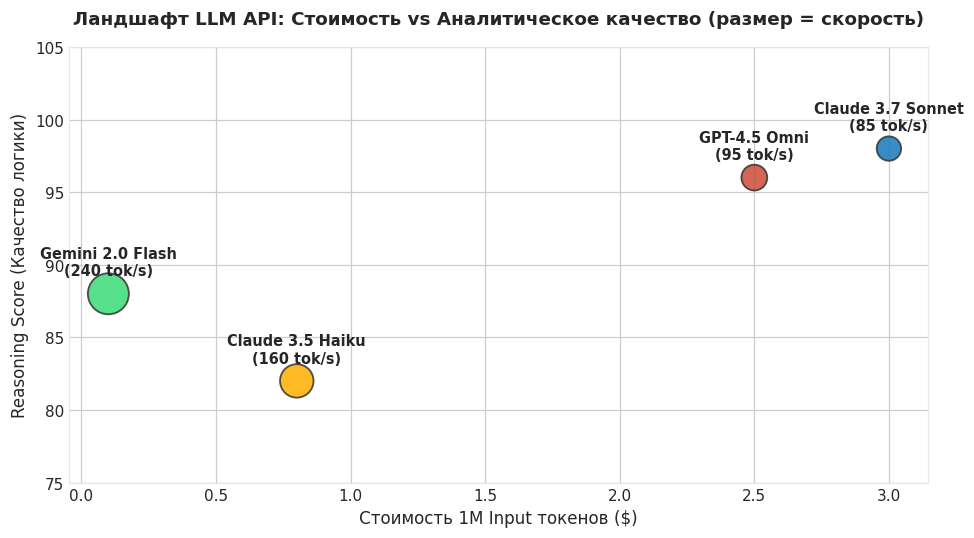

In [3]:
# Построение карты моделей
fig, ax = plt.subplots(figsize=(9, 5), dpi=110)

x = model_profiles['Стоимость 1M Input ($)']
y = model_profiles['Reasoning Score (0-100)']
sizes = model_profiles['Скорость (токенов/сек)'] * 3

scatter = ax.scatter(x, y, s=sizes, c=[PRIMARY, ALERT, SUCCESS, WARNING], 
                     edgecolors='#333333', linewidth=1.2, alpha=0.85)

for _, row in model_profiles.iterrows():
    ax.annotate(f"{row['Модель']}\n({row['Скорость (токенов/сек)']} tok/s)", 
                (row['Стоимость 1M Input ($)'], row['Reasoning Score (0-100)']),
                xytext=(0, 12), textcoords="offset points", ha='center', fontweight='bold', fontsize=9.5)

ax.set_title("Ландшафт LLM API: Стоимость vs Аналитическое качество (размер = скорость)", fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("Стоимость 1M Input токенов ($)", fontsize=11)
ax.set_ylabel("Reasoning Score (Качество логики)", fontsize=11)
ax.set_ylim(75, 105)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Расчет стоимости классификации 100k обращений
При среднем размере отзыва 150 токенов (вход) и ответе 20 токенов (выход), рассчитайте стоимость обработки 100,000 отзывов на `Gemini 2.0 Flash`.

In [4]:
### ВАШ КОД ЗДЕСЬ
total_input_tokens = 100000 * 150
total_output_tokens = 100000 * 20

cost_input = (total_input_tokens / 1000000) * 0.10
cost_output = (total_output_tokens / 1000000) * 0.40
total_cost = cost_input + cost_output

print(f"Стоимость разметки 100k отзывов: ${total_cost:.2f}!")

assert total_cost < 3.0, "Стоимость должна быть меньше $3"
print("✅ Тест успешно пройден: микроэкономика API подтверждает гигантскую рентабельность Flash-моделей!")

Стоимость разметки 100k отзывов: $2.30!
✅ Тест успешно пройден: микроэкономика API подтверждает гигантскую рентабельность Flash-моделей!


### 💡 Паттерн Model Routing
Никогда не используйте одну флагманскую модель для всех задач. Настройте шлюз (Router): 90% типовых задач классификации направляйте на Flash/Haiku, а на Sonnet/GPT-4 — только запросы с аномалиями и сложными расчетами.